# Credit Card Fraud Detection Using PyTorch

## 1. Project Overview

This project explores data preprocessing, class imbalance handling, and neural network architecture development for credit card fraud detection using the European Credit Card Fraud Detection dataset.

The objective is to prepare transaction data for a machine learning workflow and implement a feedforward neural network using PyTorch to distinguish between legitimate and fraudulent transactions.

Because fraudulent transactions represent a very small percentage of the dataset, particular attention is given to data quality, feature preprocessing, and class imbalance.

The current implementation focuses on data preparation, resampling techniques, and neural network architecture. Model training and evaluation are planned as future development.

## 2. Dataset Description

The project uses the European Credit Card Fraud Detection dataset from Kaggle.

The original dataset contains:
- 284,807 transactions.
- 492 fraudulent transactions.
- 30 input features.
- One target column (`Class`).

The target variable is:
- 0: Legitimate transaction.
- 1: Fraudulent transaction.

The features include anonymized PCA-transformed variables (`V1` through `V28`), transaction time (`Time`), and transaction amount (`Amount`).

## 3. Project Objectives

- Inspect and understand the transaction dataset.
- Clean and validate the raw data.
- Explore patterns and characteristics of fraudulent transactions.
- Prepare features for machine learning.
- Investigate techniques for handling class imbalance.
- Develop a feedforward neural network using PyTorch.
- Understand how prepared data is passed through a neural network.

Future objectives:
- Train and optimize the neural network.
- Evaluate the model's ability to detect fraudulent transactions.
- Analyze false positives and false negatives.
- Investigate classification thresholds and model performance.

## 4. Technology Stack

- **Python:** Primary programming language.
- **Jupyter Notebook:** Development environment.
- **Pandas and NumPy:** Data manipulation and numerical operations.
- **Matplotlib and Seaborn:** Data visualization.
- **Scikit-learn:** Data preprocessing and dataset splitting.
- **Imbalanced-learn:** Class imbalance techniques.
- **PyTorch:** Neural network architecture and implementation.

## 5. Project Workflow

1. Data loading and initial inspection. (Complete)
2. Data cleaning and quality validation. (Complete)
3. Exploratory data analysis (EDA). (Complete)
4. Feature preprocessing and scaling. (Complete)
5. Training and testing dataset preparation. (Complete)
6. Class imbalance handling using undersampling, oversampling, and SMOTE. (Complete)
7. PyTorch tensor preparation. (Complete)
8. Neural network architecture development. (Complete)
9. Model instantiation and forward-pass testing. (Complete)
10. Model training and optimization. (Future development)
11. Model evaluation and threshold selection. (Future development)
12. Results analysis and conclusions. (Future development)

## 6. Expected Outputs

- Cleaned transaction dataset. (Complete)
- Exploratory data analysis visualizations. (Complete)
- Preprocessed training and testing datasets. (Complete)
- Resampled training datasets using multiple techniques. (Complete)
- PyTorch tensors prepared for model input. (Complete)
- Feedforward neural network architecture. (Complete)
- Trained PyTorch neural network. (Future development)
- Model evaluation metrics, including precision, recall, F1-score, and Average Precision. (Future development)
- Confusion matrix and performance visualizations. (Future development)
- Final project findings and conclusions. (Future development)

## 7. Current Project Status

The current implementation establishes the data preprocessing pipeline and initial PyTorch neural network architecture.

The model has been instantiated and its forward pass tested using the original and resampled training datasets. Model training, optimization, and performance evaluation have not yet been implemented.

This project will be extended to include model training and evaluation in future development.

## Imports

In [87]:


# For data manipulation and analysis
import pandas as pd
import numpy as np


# For Displaying Data
import matplotlib.pyplot as plt
import seaborn as sns

# For training the Neural Network
import torch
import torch.nn as nn
import torch.optim as optim

# For Data Imbalance
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE


# For Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from pathlib import Path








## Check for CUDA(GPU)

In [88]:
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.11.0
CUDA available: False


## Project Directory and Path Configuration

In [89]:
# Define the project directory
PROJECT_ROOT = Path.cwd()

# Define data directories
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
CLEAN_DIR = DATA_DIR / "clean"
RAW_DIR = DATA_DIR / "raw"

# Define dataset paths
RAW_PATH = RAW_DIR / "creditcard.csv"
CLEAN_PATH = CLEAN_DIR / "cleaned_creditcard.csv"
LOG_PATH = RESULTS_DIR / "rejects.log"
REPORT_PATH = RESULTS_DIR / "quality_report.md"

# Create project directories if they do not exist
DATA_DIR.mkdir(exist_ok=True)
CLEAN_DIR.mkdir(exist_ok=True)
RAW_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

## Get Data

In [90]:
# Read CSV Path
df = pd.read_csv(RAW_PATH)

## Dataset Overview

In [91]:
# Data Dimensions

print(f"Dataset dimensions: {df.shape}")
print(f"Column names: {df.columns.tolist()}")

Dataset dimensions: (284807, 31)
Column names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


## Inspect First Transactions

In [92]:
df.head() # First 5 columns

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Dataset Information

In [93]:
# Dataset Info

df.info()

print(f"\nMissing values per column")
print(df.isnull().sum().sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

# Data Cleaning

The purpose of this stage is to transform the raw transaction dataset into a clean and reliable dataset suitable for machine learning.

The cleaning process will include:

1. Diagnosing class imbalance.
2. Identifying missing values.
3. Removing duplicate transactions.
4. Handling missing values.
5. Converting columns to numeric data types.
6. Validating target labels.
7. Recording rejected rows in an audit log.
8. Generating a data quality report.
9. Saving the cleaned dataset.

In [94]:

class DataCleaner:

    def __init__(self, clean_path, log_path, report_path):
        self.clean_path = Path(clean_path)
        self.log_path = Path(log_path)
        self.quality_report_path = Path(report_path)
        self.rejects = []

    # --- diagnostics -----------------------------------------------------

    def is_data_imbalanced(self, df: pd.DataFrame) -> str:
        fraud_rate = df["Class"].mean() * 100

        if fraud_rate < 1.0:
            return "Severe imbalance — use class weights and PR-AUC"

        if fraud_rate < 30.0:
            return "Imbalanced — use class weights and PR-AUC, not accuracy"

        if 45.0 <= fraud_rate <= 55.0:
            return "Balanced"

        return "Moderate imbalance"

    def missing_value_profile(self, df: pd.DataFrame) -> dict[str, int]:
        """Return the number of missing values in each affected column."""

        return {
            str(col): int(count)
            for col, count in df.isnull().sum().items()
            if count > 0
        }

    # cleaning steps 

    def _drop_duplicates(self, df: pd.DataFrame) -> pd.DataFrame:
        before = len(df)

        df = df.drop_duplicates()

        duplicate_count = before - len(df)

        self.rejects.append((duplicate_count, "duplicate rows"))

        print(f"Dropped {duplicate_count} duplicate rows")

        return df

    def _drop_null(self, df: pd.DataFrame) -> pd.DataFrame:
        before = len(df)

        df = df.dropna()

        null_count = before - len(df)

        self.rejects.append((null_count, "null rows"))

        print(f"Dropped {null_count} null rows")

        return df

    def _coerce_numeric(self, df: pd.DataFrame) -> pd.DataFrame:
        numeric_cols = (
            ["Time", "Amount"]
            + [f"V{i}" for i in range(1, 29)]
        )

        for col in numeric_cols + ["Class"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        before = len(df)

        df = df.dropna(subset=numeric_cols + ["Class"])

        bad_types_count = before - len(df)

        self.rejects.append((bad_types_count, "non-numeric values"))

        print(f"Dropped {bad_types_count} rows with non-numeric values")

        return df

    def _validate_labels(self, df: pd.DataFrame) -> pd.DataFrame:
        before = len(df)

        df = df[df["Class"].isin([0, 1])]

        bad_label_count = before - len(df)

        self.rejects.append((bad_label_count, "invalid label (not 0/1)"))

        print(f"Dropped {bad_label_count} rows with invalid labels")

        return df

    # outputs

    def _write_audit_log(self) -> None:
        self.log_path.parent.mkdir(parents=True, exist_ok=True)

        with open(self.log_path, "w") as file:
            file.write("rejected_rows,reason\n")

            for count, reason in self.rejects:
                file.write(f"{count},{reason}\n")

    def _write_quality_report(
        self,
        start: int,
        end: int,
        df: pd.DataFrame
    ) -> None:

        self.quality_report_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        fraud_rate = df["Class"].mean() * 100

        lines = [
            "# Data Quality Report",
            "",
            f"- Raw rows: {start}",
            f"- Clean rows: {end}",
            f"- Rows removed: {start - end}",
            f"- Fraud rate: {fraud_rate:.6f}%",
            f"- Imbalance verdict: {self.is_data_imbalanced(df)}",
            "",
            "## Rejections",
            "",
            "| Rows removed | Reason |",
            "|---|---|",
        ]

        for count, reason in self.rejects:
            lines.append(f"| {count} | {reason} |")

        missing = self.missing_value_profile(df)

        lines += [
            "",
            "## Remaining nulls in clean data",
            ""
        ]

        if missing:
            for col, count in missing.items():
                lines.append(f"- {col}: {count}")
        else:
            lines.append("- None")

        self.quality_report_path.write_text(
            "\n".join(lines) + "\n"
        )

    # cleaning pipeline

    def run_cleaner(self, df: pd.DataFrame) -> dict:
        """Execute the complete data-cleaning pipeline."""

        self.rejects = []

        df = df.copy()

        start = len(df)

        print(f"Starting cleaning: {start} rows")

        df = self._drop_duplicates(df)

        df = self._drop_null(df)

        df = self._coerce_numeric(df)

        df = self._validate_labels(df)

        # Write cleaning outputs
        self._write_audit_log()

        self.clean_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        df.to_csv(self.clean_path, index=False)

        self._write_quality_report(start, len(df), df)

        # Generate cleaning summary
        summary = {
            "start_rows": start,
            "end_rows": len(df),
            "rows_removed": start - len(df),
            "fraud_rate": round(float(df["Class"].mean()), 6),
            "imbalance": self.is_data_imbalanced(df),
            "rejects": self.rejects.copy(),
        }

        # Verify audit consistency
        removed = start - len(df)

        logged = sum(
            count for count, reason in self.rejects
        )

        if removed != logged:
            raise RuntimeError(
                f"Audit log incomplete: removed {removed}, logged {logged}"
            )

        print(f"Cleaning complete: {summary}")

        return summary


## Create the cleaner object

In [95]:
cleaner = DataCleaner(
    clean_path=CLEAN_PATH,
    log_path=LOG_PATH,
    report_path=REPORT_PATH
)

## Execute the cleaning pipeline

In [96]:

cleaning_summary = cleaner.run_cleaner(df)

print("DATA CLEANING SUMMARY")
print("-" * 40)

for key, value in cleaning_summary.items():
    print(f"{key}: {value}")


Starting cleaning: 284807 rows
Dropped 1081 duplicate rows
Dropped 0 null rows
Dropped 0 rows with non-numeric values
Dropped 0 rows with invalid labels
Cleaning complete: {'start_rows': 284807, 'end_rows': 283726, 'rows_removed': 1081, 'fraud_rate': 0.001667, 'imbalance': 'Severe imbalance — use class weights and PR-AUC', 'rejects': [(1081, 'duplicate rows'), (0, 'null rows'), (0, 'non-numeric values'), (0, 'invalid label (not 0/1)')]}
DATA CLEANING SUMMARY
----------------------------------------
start_rows: 284807
end_rows: 283726
rows_removed: 1081
fraud_rate: 0.001667
imbalance: Severe imbalance — use class weights and PR-AUC
rejects: [(1081, 'duplicate rows'), (0, 'null rows'), (0, 'non-numeric values'), (0, 'invalid label (not 0/1)')]


## Cleaned Dataset Inspection

Before conducting exploratory analysis, we will inspect the cleaned dataset to verify its dimensions, data types, missing values, and statistical characteristics.

In [97]:
clean_df = pd.read_csv(CLEAN_PATH)

# Inspect cleaned dataset head
clean_df.head()

# Inspect cleaned dataset dimensions
print("Dataset dimensions:", clean_df.shape)

# Inspect data types and non-null values
clean_df.info()

# Check for remaining missing values
print("\nMissing values:")
print(clean_df.isnull().sum().sum())

# Display statistical summary
clean_df.describe().T

Dataset dimensions: (283726, 31)
<class 'pandas.DataFrame'>
RangeIndex: 283726 entries, 0 to 283725
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    283726 non-null  float64
 1   V1      283726 non-null  float64
 2   V2      283726 non-null  float64
 3   V3      283726 non-null  float64
 4   V4      283726 non-null  float64
 5   V5      283726 non-null  float64
 6   V6      283726 non-null  float64
 7   V7      283726 non-null  float64
 8   V8      283726 non-null  float64
 9   V9      283726 non-null  float64
 10  V10     283726 non-null  float64
 11  V11     283726 non-null  float64
 12  V12     283726 non-null  float64
 13  V13     283726 non-null  float64
 14  V14     283726 non-null  float64
 15  V15     283726 non-null  float64
 16  V16     283726 non-null  float64
 17  V17     283726 non-null  float64
 18  V18     283726 non-null  float64
 19  V19     283726 non-null  float64
 20  V20     283726 non-null  f

,count,mean,std,min,25%,50%,75%,max
Time,283726.0,94811.077600,47481.047891,0.000000,54204.750000,84692.500000,139298.000000,172792.000000
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995


## Class Distribution Analysis

The dataset contains two transaction classes: legitimate and fraudulent.

We will examine the number and percentage of transactions belonging to each class to understand the severity of class imbalance.

Transaction Counts:
Class
0    283253
1       473
Name: count, dtype: int64

Transaction Percentages:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


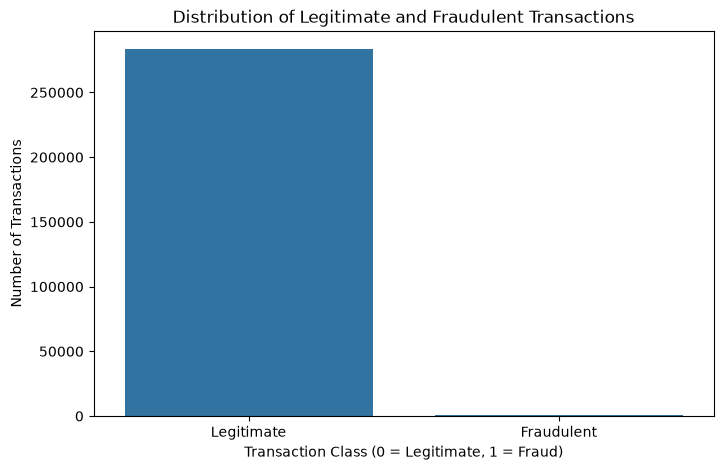

In [98]:
# Count transactions in each class
class_counts = clean_df["Class"].value_counts().sort_index()

# Calculate transaction percentages
class_percentages = clean_df["Class"].value_counts(normalize=True).sort_index() * 100

# Display class distribution
print("Transaction Counts:")
print(class_counts)

print("\nTransaction Percentages:")
print(class_percentages)

# Visualize class distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=clean_df, x="Class")

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

## Transaction Amount Analysis

We will compare transaction amounts between legitimate and fraudulent transactions.

This analysis will help identify whether transaction amounts differ between the two classes and whether extreme values are present.

Legitimate Transaction Amounts:
count    283253.000000
mean         88.413575
std         250.379023
min           0.000000
25%           5.670000
50%          22.000000
75%          77.460000
max       25691.160000
Name: Amount, dtype: float64

Fraudulent Transaction Amounts:
count     473.000000
mean      123.871860
std       260.211041
min         0.000000
25%         1.000000
50%         9.820000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


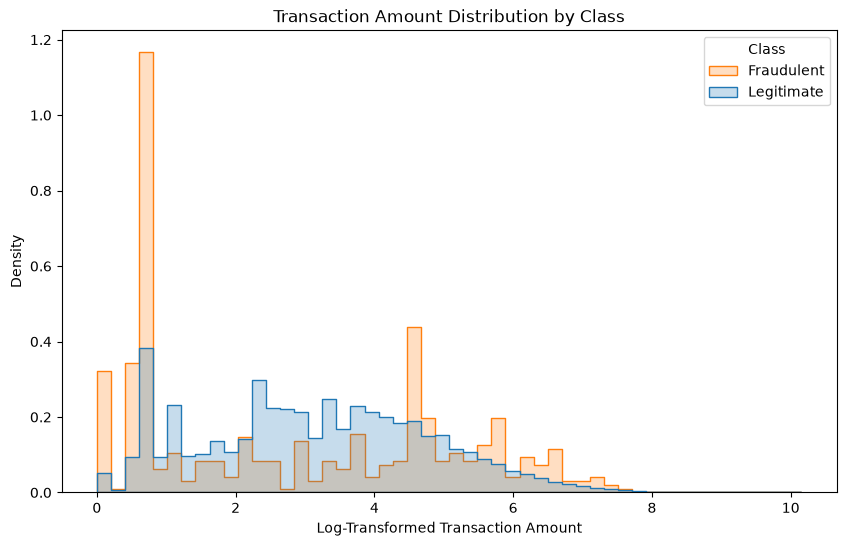

In [99]:
# Separate transaction amounts by class
legitimate_amounts = clean_df.loc[clean_df["Class"] == 0, "Amount"]
fraud_amounts = clean_df.loc[clean_df["Class"] == 1, "Amount"]

# Compare descriptive statistics
print("Legitimate Transaction Amounts:")
print(legitimate_amounts.describe())

print("\nFraudulent Transaction Amounts:")
print(fraud_amounts.describe())

# Compare amount distributions using a log transformation
plt.figure(figsize=(10, 6))

sns.histplot(
    data=clean_df,
    x=np.log1p(clean_df["Amount"]),
    hue=clean_df["Class"],
    bins=50,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Log-Transformed Transaction Amount")
plt.ylabel("Density")
plt.legend(title="Class", labels=["Fraudulent", "Legitimate"])

plt.show()

## Data PreProcessing

In [100]:
X = clean_df.drop("Class", axis=1)
y = clean_df["Class"]
X.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


## Split Data

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.15, random_state=42, stratify=y)

print(f"X_train value count: {X_train.value_counts().sum()}")
print(f"y_train value count: {y_train.value_counts().sum()}")
print(f"X_test value count: {X_test.value_counts().sum()}")
print(f"y_test value count: {y_test.value_counts().sum()}")


X_train value count: 241167
y_train value count: 241167
X_test value count: 42559
y_test value count: 42559


## Standard Scaler

In [102]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_scaled: ", X_train_scaled.shape)
print("y_test:", y_test.shape)


X_scaled:  (241167, 30)
y_test: (42559,)


## Resampling Function

In [103]:


def resample_training_data(X_train, y_train):

    # 1. No resampling (baseline)
    X_original = X_train
    y_original = y_train
    

    rus = RandomUnderSampler(random_state=42) 
    X_under, y_under = rus.fit_resample(X_train, y_train)

    ros = RandomOverSampler(random_state=42)
    X_over, y_over = ros.fit_resample(X_train, y_train)

    smote = SMOTE(random_state=42)
    X_smote, y_smote = smote.fit_resample(X_train, y_train)

    return {
        "Original": (X_original, y_original),
        "Undersampling": (X_under, y_under),
        "Oversampling": (X_over, y_over),
        "SMOTE": (X_smote, y_smote)
    }

    



## Execute the Resampling Function

In [104]:
resampled_data = resample_training_data(X_train_scaled, y_train)



## Convert Data to Pytorch 

In [105]:


tensor_data = {}

# Convert all resampling strategies into PyTorch tensors

tensor_data = {}

for name, (X_resampled, y_resampled) in resampled_data.items():

    # Convert training features into tensors
    X_tensor = torch.tensor(
        X_resampled,
        dtype=torch.float32
    )

    # Convert training labels into tensors
    y_tensor = torch.tensor(
        y_resampled.to_numpy(),
        dtype=torch.float32
    )

    # Store tensors under their respective strategy names
    tensor_data[name] = (X_tensor, y_tensor)


# Convert original testing data into PyTorch tensors

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
)


# Display tensor shapes for each strategy

for name, (X_tensor, y_tensor) in tensor_data.items():

    print(f"\n{name}")
    print("Training features:", X_tensor.shape)
    print("Training labels:", y_tensor.shape)


# Display testing tensor shapes

print("\nTesting features:", X_test_tensor.shape)
print("Testing labels:", y_test_tensor.shape)


# Display data types

print("\nFeature data type:", X_test_tensor.dtype)
print("Label data type:", y_test_tensor.dtype)


Original
Training features: torch.Size([241167, 30])
Training labels: torch.Size([241167])

Undersampling
Training features: torch.Size([804, 30])
Training labels: torch.Size([804])

Oversampling
Training features: torch.Size([481530, 30])
Training labels: torch.Size([481530])

SMOTE
Training features: torch.Size([481530, 30])
Training labels: torch.Size([481530])

Testing features: torch.Size([42559, 30])
Testing labels: torch.Size([42559])

Feature data type: torch.float32
Label data type: torch.float32


## Neural Network Architecture

In [106]:
class FraudDetection(nn.Module):

    def __init__(self):
        super().__init__()

        # Hidden layer 1: 30 input features -> 64 neurons
        self.layer1 = nn.Linear(30, 64)

        # Hidden layer 2: 64 neurons -> 32 neurons
        self.layer2 = nn.Linear(64, 32)

        # Binary classification output: 32 inputs -> 1 logit
        self.output_layer = nn.Linear(32, 1)

        # ReLU activation introduces non-linearity
        self.relu = nn.ReLU()

    def forward(self, x):

        # First hidden layer
        x = self.relu(self.layer1(x))

        # Second hidden layer
        x = self.relu(self.layer2(x))

        # Return raw logits for BCEWithLogitsLoss
        x = self.output_layer(x)

        return x

## Instantiate and test the model.

In [107]:
model = FraudDetection()

print(model)


# Count the total number of learnable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("\nTotal learnable parameters:", total_parameters)


# Test the model

for name, (X_train_tensor, y_train_tensor) in tensor_data.items(): # resampled options (Original, Undersampling, Oversampling, SMOTE)
    
    with torch.no_grad():
        sample_output = model(X_train_tensor[:5])

    print(f"\nStrategy: {name}")
    print(f"Output: {sample_output}")
    print(f"Output shape: {sample_output.shape}")



FraudDetection(
  (layer1): Linear(in_features=30, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)

Total learnable parameters: 4097

Strategy: Original
Output: tensor([[-0.0718],
        [-0.0361],
        [-0.0682],
        [-0.0197],
        [ 0.1231]])
Output shape: torch.Size([5, 1])

Strategy: Undersampling
Output: tensor([[-0.0067],
        [ 0.0147],
        [ 0.0391],
        [-0.1173],
        [ 0.0472]])
Output shape: torch.Size([5, 1])

Strategy: Oversampling
Output: tensor([[-0.0718],
        [-0.0361],
        [-0.0682],
        [-0.0197],
        [ 0.1231]])
Output shape: torch.Size([5, 1])

Strategy: SMOTE
Output: tensor([[-0.0718],
        [-0.0361],
        [-0.0682],
        [-0.0197],
        [ 0.1231]])
Output shape: torch.Size([5, 1])
